<a href="https://colab.research.google.com/github/ahmed-abo-el3ela/assymint-of-data-science-code/blob/main/S11%20Real%20estate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.linear_model import LinearRegression, Lasso, Ridge
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error , mean_squared_error
from sklearn.preprocessing import StandardScaler

In [ ]:
df = pd.read_csv('/content/Real estate.csv')

#EDA

In [ ]:
df

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...,...,...
409,410,2013.000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,411,2012.667,5.6,90.45606,9,24.97433,121.54310,50.0
411,412,2013.250,18.8,390.96960,7,24.97923,121.53986,40.6
412,413,2013.000,8.1,104.81010,5,24.96674,121.54067,52.5


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


In [ ]:
df.describe()#هنا انا ببدا اطبق كل اللي تحت
#هنا الايج ب صفر في المينيمام ق عايزه تتعدل هي و المسافه اللي بصفر

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,207.500000,2013.148971,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,119.655756,0.281967,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,1.000000,2012.667000,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,104.250000,2012.917000,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,207.500000,2013.167000,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,310.750000,2013.417000,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,414.000000,2013.583000,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


In [ ]:
df.isna().sum()#معندناش اي ميسينج فاليو

,0
No,0
X1 transaction date,0
X2 house age,0
X3 distance to the nearest MRT station,0
X4 number of convenience stores,0
X5 latitude,0
X6 longitude,0
Y house price of unit area,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
#sns.pairplot(df)#هنا اعرف في ريليشان شيب للكولومز مع بعض القطر الرئيسي

In [ ]:
df.corr()['Y house price of unit area']#هنعمل دروب بناء ع انه مفيش ريليشن هنعمل ل اول اتنين و هنشتغل ع الباقي

,Y house price of unit area
No,-0.028587
X1 transaction date,0.087491
X2 house age,-0.210567
X3 distance to the nearest MRT station,-0.673613
X4 number of convenience stores,0.571005
X5 latitude,0.546307
X6 longitude,0.523287
Y house price of unit area,1.000000


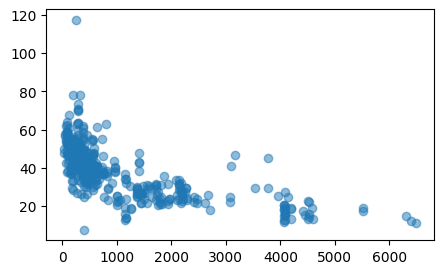

In [ ]:
#هنرسم
plt.figure(figsize=(5,3))
plt.scatter(df['X3 distance to the nearest MRT station'], df['Y house price of unit area'], alpha=.5) # Added the 'y' argument
#sns.heatmap(df.corr(),annot=True)

#data pre

In [ ]:
#Drob('no,X1 transaction date')
df= df.drop(columns=['No','X1 transaction date'])

#مينفعش العمر يبقا ب صفر هنعمل ريبلاس للزيرو بنان بعد كده هنهدل النان

In [ ]:
#chek if coi age 0
sum(df['X2 house age']==0)

17

In [ ]:
#rep 0 to nan
df['X2 house age']=df['X2 house age'].replace(0,np.nan)
df['X2 house age'].isna().sum()

np.int64(17)

In [ ]:
df['X2 house age'].fillna(df['X2 house age'].median())

,X2 house age
0,32.0
1,19.5
2,13.3
3,13.3
4,5.0
...,...
409,13.7
410,5.6
411,18.8
412,8.1


In [ ]:
df['X2 house age']=df['X2 house age'].fillna(df['X2 house age'].median())

In [ ]:
df['X2 house age'].isna().sum()

np.int64(0)

In [ ]:
#هل في اوت لايارز ولا لا
px.box(df,x='X2 house age')

In [ ]:
px.box(df,x='Y house price of unit area')

In [ ]:
#هنعمل فيلتر للابر drop outlai of y house.....
upper=73.6
new_df=df[df['Y house price of unit area']<=upper]

In [ ]:
px.box(new_df,x='Y house price of unit area')

#Data Split

In [ ]:
x = new_df.drop(columns='Y house price of unit area')
y = new_df['Y house price of unit area']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(x, y,train_size =0.75, random_state=42)

In [ ]:
scale = StandardScaler()
scale.fit(X_train)
X_train_scaled = scale.transform(X_train)
X_test_scaled = scale.transform(X_test)

#buld model

In [ ]:
lr=LinearRegression().fit(X_train_scaled,y_train)

In [ ]:
y_pred = lr.predict(X_test_scaled)

In [ ]:
mean_absolute_error(y_test,y_pred)

5.968947530380692

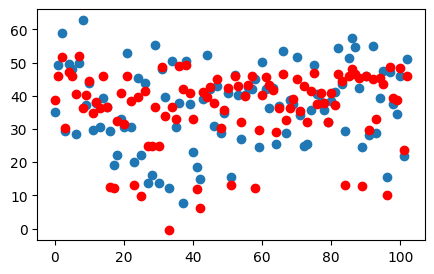

In [ ]:
plt.figure(figsize=(5,3))
plt.scatter(np.arange(len(y_test)),y_test)
plt.scatter(np.arange(len(y_pred)),y_pred, color ='red')